# Antenna Tilt — 1b: one sector + demand, and the coverage/capacity tension

Stage 1a gave a single sector's spatial radio model. 1b puts **users** on it: a demand field
$\rho(x,y)$ over the sector's service region, and the $\rho$-weighted metrics that turn the field into
numbers an optimizer can target. New logic lives in `telecomopt.coverage` (tests in
`tests/test_coverage.py`); this notebook imports it and tells the story.

**Decisions carried in (decision log):** the service region is the sector's $\pm60°$ **wedge** out to
**half-ISD ($d_{\max}=250$ m)**, excluding the near-tower floor $d_{\min}=35$ m (D09). Single sector ⇒
no interferers ⇒ SINR = SNR. Three metrics, kept **separate** (OQ9): served fraction, 5th-percentile
cell-edge, and mean Shannon spectral efficiency. We optimize tilt under **each** and show they disagree
— the coverage/capacity tension. $\rho$'s meaning (uniform area vs user density) is itself a choice.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from telecomopt.rf import RFParams
from telecomopt.coverage import *

In [2]:
p = RFParams()
dist, az, area = sample_wedge(d_min=35.0, d_max=250.0, half_az_deg=60.0, n_r=60, n_az=61)
x, y = to_xy(dist, az)
print(f"{dist.size} sample points over the +/-60 deg wedge, {35:.0f}-{250:.0f} m; "
      f"total area {area.sum()/1e3:.1f} x10^3 m^2")

3660 sample points over the +/-60 deg wedge, 35-250 m; total area 64.2 x10^3 m^2


## 1. The demand field $\rho(x,y)$

$\rho$ says *whose experience* we optimize. **Uniform** $\rho=1$ gives area-based metrics (every patch
of ground counts equally). **User density** concentrates weight where people are — here a Gaussian
hotspot. The optimizer will then care about those users, not empty ground.

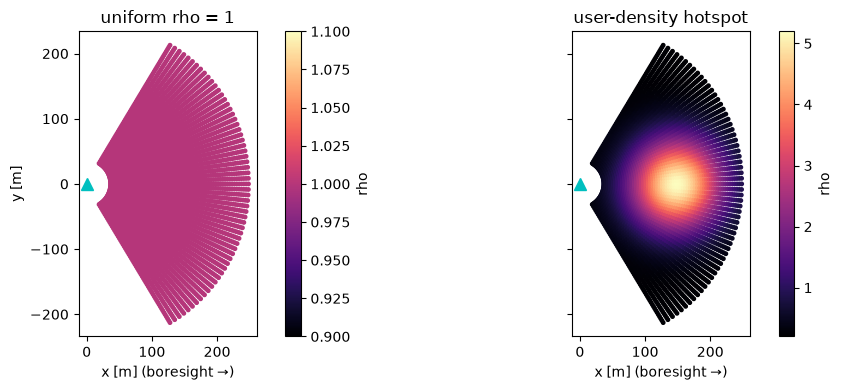

In [3]:
dem_uniform = uniform_demand(dist, az)

# a user-density field with one hotspot ~150 m out on boresight (sigma 50 m, peak 5),
# on a small background floor so the edges are not exactly zero.
 
dem_hotspot = hotspot_demand(x, y, centers=[(150.0, 0.0)], sigmas=[50.0], peaks=[5.0], floor=0.2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for axn, (title, dem) in zip(axes, [("uniform rho = 1", dem_uniform), ("user-density hotspot", dem_hotspot)]):
    sc = axn.scatter(x, y, c=dem, s=6, cmap="magma")
    axn.plot(0, 0, "c^", ms=9); axn.set_aspect("equal")
    axn.set_title(title); axn.set_xlabel("x [m] (boresight →)")
    fig.colorbar(sc, ax=axn, label="rho")
axes[0].set_ylabel("y [m]")
plt.tight_layout(); plt.show()

## 2. The three metrics at one tilt

`coverage_report` computes all three, $\rho$-weighted (weight = demand × area), from the per-point
spectral efficiency. Note the **service threshold** below: at a realistic bar (SE ≥ 1 bps/Hz) a lone
noise-limited sector clears it *everywhere*, so served-fraction saturates — it can't rank tilts here.
That is the blunt-in-1b behaviour we expected; served-fraction comes alive only with interference
(Stage 2). The 5th-percentile and mean do the discriminating in 1b.

In [4]:
rep = coverage_report(8.0, dist, az, dem_uniform, area, threshold=1.0)
print("uniform demand, tilt 8 deg:")
for k, v in rep.items():
    print(f"  {k:16s} = {v:.3f}")

uniform demand, tilt 8 deg:
  mean_se          = 14.782
  p5_se            = 12.441
  served_fraction  = 1.000


## 3. Optimize under each objective — the coverage/capacity tension

Sweep the (electrical) tilt and read each metric. **Capacity** (mean SE) and **cell-edge**
(5th-percentile) peak at *different* tilts: capacity likes a slightly steeper beam that pulls in the
strong near-tower users, cell-edge likes a shallower beam that reaches the weak edge. No single tilt is
best for both — that is the tension the whole problem is about.

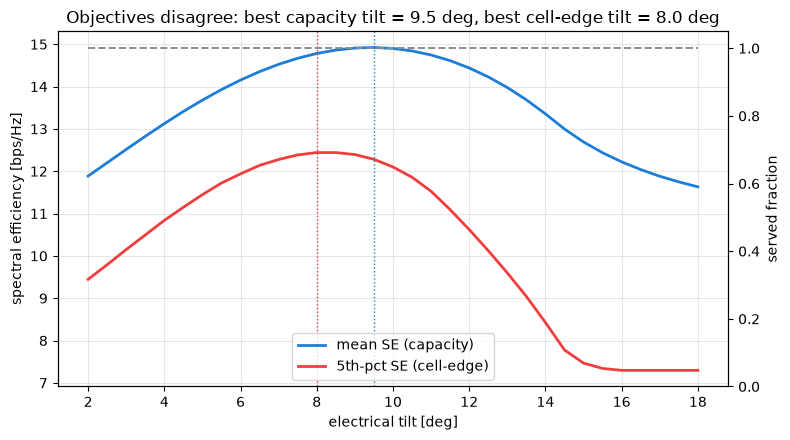

In [ ]:
tilts = np.arange(2.0, 18.1, 0.5)

# run coverage_report at each tilt (uniform demand), then pull out the three curves.
reps = [coverage_report(t, dist, az, dem_uniform, area, threshold=1.0) for t in tilts]
mean_se = np.array([r["mean_se"] for r in reps])
p5 = np.array([r["p5_se"] for r in reps])
sf = np.array([r["served_fraction"] for r in reps])

fig, axL = plt.subplots(figsize=(8, 4.5))
axL.plot(tilts, mean_se, color="#1c7ed6", lw=2, label="mean SE (capacity)")
axL.plot(tilts, p5, color="#f03e3e", lw=2, label="5th-pct SE (cell-edge)")
axL.axvline(tilts[np.argmax(mean_se)], color="#1c7ed6", ls=":", lw=1)
axL.axvline(tilts[np.argmax(p5)], color="#f03e3e", ls=":", lw=1)
axL.set_xlabel("electrical tilt [deg]"); axL.set_ylabel("spectral efficiency [bps/Hz]")
axR = axL.twinx()
axR.plot(tilts, sf, color="#868e96", lw=1.4, ls="--", label="served frac (SE≥1)")
axR.set_ylabel("served fraction"); axR.set_ylim(0, 1.05)
axL.legend(loc="lower center"); axL.grid(alpha=0.3)
axL.set_title(f"Objectives disagree: best capacity tilt = {tilts[np.argmax(mean_se)]:.1f} deg, "
              f"best cell-edge tilt = {tilts[np.argmax(p5)]:.1f} deg")
plt.tight_layout(); plt.show()

## 4. The coverage/capacity frontier

Plotting cell-edge against capacity across tilts traces the trade-off directly: you cannot move up-right
freely — improving one past a point costs the other. The two coloured points are the capacity-optimal and
cell-edge-optimal tilts; a real operator picks a point on this frontier by policy.

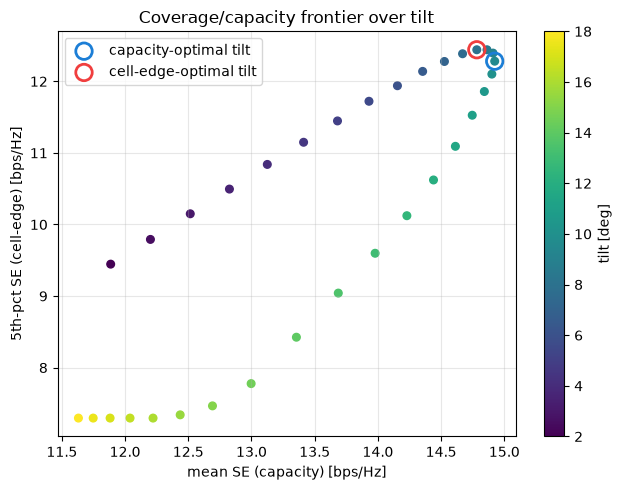

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(mean_se, p5, c=tilts, cmap="viridis", s=30)
ax.scatter(mean_se[np.argmax(mean_se)], p5[np.argmax(mean_se)], s=140, facecolors="none",
           edgecolors="#1c7ed6", lw=2, label="capacity-optimal tilt")
ax.scatter(mean_se[np.argmax(p5)], p5[np.argmax(p5)], s=140, facecolors="none",
           edgecolors="#f03e3e", lw=2, label="cell-edge-optimal tilt")
ax.set_xlabel("mean SE (capacity) [bps/Hz]"); ax.set_ylabel("5th-pct SE (cell-edge) [bps/Hz]")
fig.colorbar(sc, label="tilt [deg]"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Coverage/capacity frontier over tilt")
plt.tight_layout(); plt.show()

## 5. The optimum moves with demand (our own result)

With the model in hand we can ask *how the best tilt depends on where
the users are*. Concentrate demand **near** the tower and the cell-edge-optimal tilt steepens (aim the beam
down at them); push demand to the **edge** and it shallows (reach them). This is exactly the demand-driven
CCO idea (OQ9) made concrete on our own model.

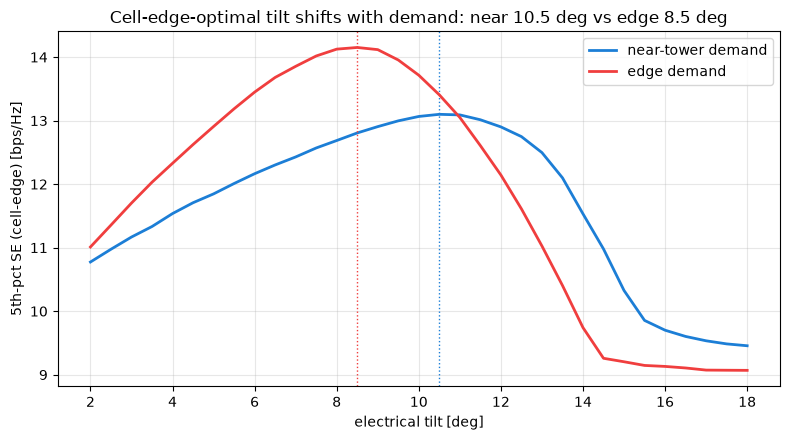

In [8]:
near = hotspot_demand(x, y, centers=[(60.0, 0.0)], sigmas=[40.0], peaks=[5.0], floor=0.1)
edge = hotspot_demand(x, y, centers=[(230.0, 0.0)], sigmas=[40.0], peaks=[5.0], floor=0.1)

# the 5th-pct cell-edge curve vs tilt for each demand field (same pattern as section 3).
p5_near = np.array([coverage_report(t, dist, az, near, area)["p5_se"] for t in tilts])
p5_edge = np.array([coverage_report(t, dist, az, edge, area)["p5_se"] for t in tilts])

fig, ax = plt.subplots(figsize=(8, 4.5))
for lbl, curve, col in [("near-tower demand", p5_near, "#1c7ed6"), ("edge demand", p5_edge, "#f03e3e")]:
    ax.plot(tilts, curve, lw=2, color=col, label=lbl)
    ax.axvline(tilts[np.argmax(curve)], color=col, ls=":", lw=1)
ax.set_xlabel("electrical tilt [deg]"); ax.set_ylabel("5th-pct SE (cell-edge) [bps/Hz]")
ax.set_title(f"Cell-edge-optimal tilt shifts with demand: "
             f"near {tilts[np.argmax(p5_near)]:.1f} deg vs edge {tilts[np.argmax(p5_edge)]:.1f} deg")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Stage 1b complete.** One sector now has a demand field and three $\rho$-weighted metrics, the
coverage/capacity tension is explicit, and we have a self-generated result: the optimal tilt tracks the
demand. All of it restricted to the D09-valid wedge.

**Stage 2** adds a **second sector**: best-server assignment (each point served by the strongest antenna),
real **interference** (SINR, not SNR) in the overlap — where served-fraction finally starts to
discriminate — and the first *coupled* tilt trade-off. The **moving-frame** decomposition (OQ1) and the
QUBO/QAOA solve follow as the network grows.